In [1]:
from __future__ import annotations

import ast
import csv
import json
import logging
import os
import re
import sqlite3
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    def display(value: object) -> None:
        print(value)

In [2]:
CATEGORICAL_FEATURES = ["subscription_type", "reported_income"]

NUMERIC_FEATURES = [
    "tenure_days",
    "order_count",
    "total_spend",
    "recency_days",
    "subscription_order_count",
    "retail_spend_share",
    "late_delivery_rate",
    "undelivered_rate",
    "avg_delivery_delay_days",
    "pct_cardpay",
    "pct_directdebit",
    "dog_item_share",
    "cat_item_share",
    "small_animal_item_share",
    "review_count",
    "avg_star_rating",
    "complaint_count",
    "query_count",
    "days_since_last_contact",
    "login_count",
    "days_since_last_login",
    "mobile_login_share",
    "survey_responded",
    "nps_recommend",
    "satisfaction_score",
    "online_comparison_freq",
    "has_review",
    "has_crm_contact",
]

LABEL = "churn"
ID_COLUMN = "customer_id"
LEAKAGE_COLUMNS = [
    "auto_renew",
    "end_date",
    "start_date",
    "subscription_length_days",
    "subscription_ended_before_snapshot",
    "delivery_service",
]

PET_GROUPS = {
    "Dog Food": "dog",
    "Dog Toys": "dog",
    "Dog Treats": "dog",
    "Cat Litter": "cat",
    "Cat Toys": "cat",
    "Cat Accessories": "cat",
    "Cat Food": "cat",
    "Cat Treats": "cat",
    "Small Animal Food": "small_animal",
    "Small Animal Toys": "small_animal",
    "Small Animal Treats": "small_animal",
    "Small Animal Bedding": "small_animal",
    "Small Animal Accessories": "small_animal",
}

SURVEY_SCORE_COLUMNS = ["nps_recommend", "satisfaction_score", "online_comparison_freq"]
DEVICE_PATTERN = re.compile(r"\((Desktop/Laptop|Mobile|Tablet)\b", re.IGNORECASE)


class DataQualityError(RuntimeError):
    """Raised when a check fails hard enough that the Parquet file must not be written."""


@dataclass
class Check:
    name: str
    status: str
    detail: str


def find_project_root() -> Path:
    """Find the folder that holds the SQLite extract, walking up from the working directory."""
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "PerfectPetClub.db").exists():
            return candidate
    raise FileNotFoundError(
        "PerfectPetClub.db is not in the working directory or a parent. "
        "Open this notebook from the project folder."
    )


def configure_logging(log_path: Path) -> logging.Logger:
    """Log to the notebook stream and to logs/etl.log. Re-running the cell replaces handlers."""
    log_path.parent.mkdir(parents=True, exist_ok=True)
    logger = logging.getLogger("perfectpet.etl")
    logger.handlers.clear()
    logger.setLevel(logging.INFO)
    logger.propagate = False
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(message)s")
    file_handler = logging.FileHandler(log_path, encoding="utf-8")
    file_handler.setFormatter(formatter)
    stream_handler = logging.StreamHandler()
    stream_handler.setFormatter(formatter)
    logger.addHandler(file_handler)
    logger.addHandler(stream_handler)
    return logger


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
LOG_PATH = PROJECT_ROOT / "logs" / "etl.log"
PARQUET_PATH = DATA_DIR / "customer_churn.parquet"
CONTRACT_PATH = DATA_DIR / "feature_contract.json"
QUALITY_PATH = DATA_DIR / "data_quality_report.csv"
LOGGER = configure_logging(LOG_PATH)
sns.set_theme(style="whitegrid")
LOGGER.info("Project root %s", PROJECT_ROOT)

2026-11-14 17:17:18,112 INFO Project root D:\data engineering_herts


In [4]:
def parse_platform(value: object) -> str:
    """Turn values such as `['e-mail']` into email, telephone or live_chat."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return "unknown"
    text = str(value).strip()
    try:
        parsed = ast.literal_eval(text)
    except (ValueError, SyntaxError):
        parsed = text
    if isinstance(parsed, list) and parsed:
        text = str(parsed[0])
    elif isinstance(parsed, str):
        text = parsed
    key = text.strip().lower().replace("_", "-")
    mapping = {
        "e-mail": "email",
        "email": "email",
        "telephone": "telephone",
        "phone": "telephone",
        "live-chat": "live_chat",
        "live chat": "live_chat",
    }
    return mapping.get(key, "unknown")


def device_class(user_agent: object) -> str:
    """Read the device family from the user-agent token. Anything else is unknown."""
    if not isinstance(user_agent, str):
        return "unknown"
    match = DEVICE_PATTERN.search(user_agent)
    if match is None:
        return "unknown"
    label = match.group(1).lower()
    if label.startswith("desktop"):
        return "desktop"
    return label


def pet_group(category_name: object) -> str:
    """Collapse catalogue categories into dog, cat, small_animal or other."""
    if category_name is None or pd.isna(category_name):
        return "unknown"
    return PET_GROUPS.get(str(category_name), "other")


def clean_income(value: object) -> str:
    if value is None or (isinstance(value, float) and np.isnan(value)) or pd.isna(value):
        return "Not provided"
    text = str(value).strip()
    if text == "" or text.lower() == "nan":
        return "Not provided"
    return text


def run_parser_checks() -> None:
    """Lock the parsers. These do not need the source files."""
    assert parse_platform("['e-mail']") == "email"
    assert parse_platform("['telephone']") == "telephone"
    assert parse_platform("['live-chat']") == "live_chat"
    assert parse_platform("carrier pigeon") == "unknown"
    assert device_class("Mozilla/5.0 (Mobile; Titan) AppleWebKit") == "mobile"
    assert device_class("Mozilla/5.0 (Tablet; Slate) AppleWebKit") == "tablet"
    assert device_class("Mozilla/5.0 (Desktop/Laptop; Air) AppleWebKit") == "desktop"
    assert device_class("not a user agent") == "unknown"
    assert pet_group("Dog Food") == "dog"
    assert pet_group("Cat Treats") == "cat"
    assert pet_group("Grooming") == "other"
    assert pet_group(None) == "unknown"
    assert clean_income("  £30k ") == "£30k"
    assert clean_income(None) == "Not provided"
    LOGGER.info("Parser checks passed")


run_parser_checks()

2026-11-14 17:17:18,164 INFO Parser checks passed


In [6]:
def determine_as_of(sales: pd.DataFrame, crm: pd.DataFrame, logs: pd.DataFrame) -> pd.Timestamp:
    candidates = [sales["order_date"].max(), crm["contacted_at"].max(), logs["logged_in_at"].max()]
    observed = [pd.Timestamp(value) for value in candidates if pd.notna(value)]
    if not observed:
        raise DataQualityError("Could not determine a snapshot timestamp")
    as_of = max(observed)
    LOGGER.info("Snapshot as_of %s", as_of)
    return as_of


def build_subscription_frame(
    customers: pd.DataFrame,
    subscriptions: pd.DataFrame,
    subscription_types: pd.DataFrame,
    as_of: pd.Timestamp,
) -> pd.DataFrame:
    """Attach the plan and the label. Also builds the columns we deliberately do not model."""
    plans = subscriptions.merge(subscription_types, on="subscription_type_id", how="left", validate="m:1")
    frame = customers.merge(plans, on="subscription_id", how="left", validate="m:1")
    if frame["auto_renew"].isna().any():
        raise DataQualityError("A customer subscription is missing auto_renew")
    frame["churn"] = np.where(frame["auto_renew"].eq(0), 1, 0).astype("int64")
    frame["tenure_days"] = (as_of - frame["start_date"]).dt.total_seconds() / 86400.0
    frame["subscription_length_days"] = (frame["end_date"] - frame["start_date"]).dt.total_seconds() / 86400.0
    frame["subscription_ended_before_snapshot"] = (frame["end_date"] < as_of).astype("int64")
    plan_to_delivery = frame.groupby("subscription_type")["delivery_service"].nunique()
    if (plan_to_delivery != 1).any():
        raise DataQualityError(
            "delivery_service is no longer determined by subscription_type. "
            "Decide whether to keep it before loading."
        )
    return frame


def leakage_report(subscriptions: pd.DataFrame) -> pd.DataFrame:
    """Show why end_date cannot be a feature. This frame is not passed to load."""
    report = (
        subscriptions.groupby("subscription_ended_before_snapshot", as_index=False)
        .agg(customers=(ID_COLUMN, "size"), churn_rate=(LABEL, "mean"), mean_length_days=("subscription_length_days", "mean"))
    )
    report["subscription_ended_before_snapshot"] = report["subscription_ended_before_snapshot"].map(
        {0: "still active at snapshot", 1: "already ended at snapshot"}
    )
    return report

In [ ]:

































































































































































































































































































































































def _rate(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """0 when the activity never happened, otherwise the share."""
    return np.where(denominator > 0, numerator / denominator, 0.0)


def build_sales_features(
    customers: pd.DataFrame,
    sales: pd.DataFrame,
    sale_products: pd.DataFrame,
    products: pd.DataFrame,
    categories: pd.DataFrame,
    payments: pd.DataFrame,
    as_of: pd.Timestamp,
) -> pd.DataFrame:
    """Order, delivery, payment-mix and pet-mix features at customer grain."""
    orders = sales.merge(payments, on="payment_id", how="left", validate="m:1")
    orders["is_late"] = (
        orders["delivered_date"].notna() & orders["expected_date"].notna() & (orders["delivered_date"] > orders["expected_date"])
    )
    orders["is_undelivered"] = orders["delivered_date"].isna()
    orders["delay_days"] = (orders["delivered_date"] - orders["expected_date"]).dt.total_seconds() / 86400.0

    lines = sale_products.merge(
        products[["product_id", "price", "product_category_id", "is_subscription"]],
        on="product_id",
        how="left",
        validate="m:1",
    )
    lines = lines.merge(categories, on="product_category_id", how="left")
    lines = lines.merge(sales[["sale_id", "customer_id"]], on="sale_id", how="left", validate="m:1")
    lines["line_value"] = lines["quantity"] * lines["price"]
    lines["pet_group"] = lines["category_name"].map(pet_group)
    lines.loc[lines["is_subscription"].fillna(False), "pet_group"] = "subscription"

    basket = lines.groupby("sale_id", as_index=False)["line_value"].sum().rename(columns={"line_value": "basket_value"})
    retail_basket = (
        lines.loc[~lines["is_subscription"].fillna(False)]
        .groupby("sale_id")["line_value"]
        .sum()
        .rename("retail_value")
    )
    orders = orders.merge(basket, on="sale_id", how="left").merge(retail_basket, on="sale_id", how="left")
    orders["retail_value"] = orders["retail_value"].fillna(0.0)
    orders["basket_value"] = orders["basket_value"].fillna(0.0)
    orders["retail_paid"] = np.where(
        orders["basket_value"] > 0,
        orders["amount"] * orders["retail_value"] / orders["basket_value"],
        0.0,
    )
    subscription_sales = set(lines.loc[lines["is_subscription"].fillna(False), "sale_id"])
    orders["is_subscription_order"] = orders["sale_id"].isin(subscription_sales)

    order_totals = orders.groupby("customer_id", as_index=False).agg(
        order_count=("sale_id", "size"),
        total_spend=("amount", "sum"),
        retail_paid=("retail_paid", "sum"),
        last_order=("order_date", "max"),
        late_deliveries=("is_late", "sum"),
        undelivered_orders=("is_undelivered", "sum"),
        avg_delivery_delay_days=("delay_days", "mean"),
        subscription_order_count=("is_subscription_order", "sum"),
    )
    gateway_counts = orders.groupby(["customer_id", "payment_gateway"]).size().unstack(fill_value=0)
    gateway_share = gateway_counts.div(gateway_counts.sum(axis=1), axis=0)

    retail_lines = lines.loc[~lines["is_subscription"].fillna(False)].copy()
    pet_qty = retail_lines.groupby(["customer_id", "pet_group"])["quantity"].sum().unstack(fill_value=0)
    pet_total = pet_qty.sum(axis=1).replace(0, np.nan)

    features = customers[[ID_COLUMN]].drop_duplicates().merge(order_totals, on=ID_COLUMN, how="left", validate="1:1")
    for column in ["order_count", "total_spend", "retail_paid", "late_deliveries", "undelivered_orders", "subscription_order_count"]:
        features[column] = features[column].fillna(0)
    features["recency_days"] = (as_of - features["last_order"]).dt.total_seconds() / 86400.0
    features["retail_spend_share"] = _rate(features["retail_paid"], features["total_spend"])
    features["late_delivery_rate"] = _rate(features["late_deliveries"], features["order_count"])
    features["undelivered_rate"] = _rate(features["undelivered_orders"], features["order_count"])
    features["subscription_order_count"] = features["subscription_order_count"].astype("int64")
    features["order_count"] = features["order_count"].astype("int64")

    for gateway in ["cardpay", "directdebit"]:
        column = f"pct_{gateway}"
        if gateway in gateway_share.columns:
            features[column] = features[ID_COLUMN].map(gateway_share[gateway]).fillna(0.0)
        else:
            features[column] = 0.0

    for group, column in [("dog", "dog_item_share"), ("cat", "cat_item_share"), ("small_animal", "small_animal_item_share")]:
        if group in pet_qty.columns:
            share = (pet_qty[group] / pet_total).fillna(0.0)
            features[column] = features[ID_COLUMN].map(share).fillna(0.0)
        else:
            features[column] = 0.0
    keep = [
        ID_COLUMN,
        "order_count",
        "total_spend",
        "recency_days",
        "subscription_order_count",
        "retail_spend_share",
        "late_delivery_rate",
        "undelivered_rate",
        "avg_delivery_delay_days",
        "pct_cardpay",
        "pct_directdebit",
        "dog_item_share",
        "cat_item_share",
        "small_animal_item_share",
    ]
    return features[keep]


def build_review_features(customers: pd.DataFrame, reviews: pd.DataFrame) -> pd.DataFrame:
    totals = reviews.groupby("customer_id", as_index=False).agg(
        review_count=("review_id", "size"),
        avg_star_rating=("star_rating", "mean"),
    )
    features = customers[[ID_COLUMN]].drop_duplicates().merge(totals, on=ID_COLUMN, how="left", validate="1:1")
    features["review_count"] = features["review_count"].fillna(0).astype("int64")
    features["has_review"] = features["review_count"].gt(0).astype("int64")
    return features


def build_crm_features(customers: pd.DataFrame, crm: pd.DataFrame, as_of: pd.Timestamp) -> pd.DataFrame:
    working = crm.loc[crm["customer_id"].isin(customers[ID_COLUMN])].copy()
    complaints = working.loc[working["contact_type"] == "complaint"].groupby("customer_id").size()
    queries = working.loc[working["contact_type"] == "query"].groupby("customer_id").size()
    last_contact = working.groupby("customer_id")["contacted_at"].max()
    features = customers[[ID_COLUMN]].drop_duplicates()
    features["complaint_count"] = features[ID_COLUMN].map(complaints).fillna(0).astype("int64")
    features["query_count"] = features[ID_COLUMN].map(queries).fillna(0).astype("int64")
    last_contact_at = pd.to_datetime(features[ID_COLUMN].map(last_contact))
    features["days_since_last_contact"] = (as_of - last_contact_at).dt.total_seconds() / 86400.0
    features["has_crm_contact"] = features[ID_COLUMN].isin(working["customer_id"]).astype("int64")
    return features


def build_login_features(customers: pd.DataFrame, logs: pd.DataFrame, as_of: pd.Timestamp) -> pd.DataFrame:
    known = customers[[ID_COLUMN, "email"]].drop_duplicates()
    matched = logs.merge(known, on="email", how="inner")
    totals = matched.groupby(ID_COLUMN, as_index=False).agg(
        login_count=("session_id", "size"),
        last_login=("logged_in_at", "max"),
    )
    mobile = matched.loc[matched["device"] == "mobile"].groupby(ID_COLUMN).size()
    features = known[[ID_COLUMN]].merge(totals, on=ID_COLUMN, how="left", validate="1:1")
    features["login_count"] = features["login_count"].fillna(0).astype("int64")
    features["days_since_last_login"] = (as_of - features["last_login"]).dt.total_seconds() / 86400.0
    features["mobile_login_share"] = _rate(features[ID_COLUMN].map(mobile).fillna(0.0), features["login_count"])
    return features[[ID_COLUMN, "login_count", "days_since_last_login", "mobile_login_share"]]


def build_survey_features(customers: pd.DataFrame, survey: pd.DataFrame) -> pd.DataFrame:
    features = customers[[ID_COLUMN, "email"]].drop_duplicates().merge(survey, on="email", how="left", validate="1:1")
    features["survey_responded"] = features["email"].isin(set(survey["email"])).astype("int64")
    features["reported_income"] = features["reported_income"].apply(clean_income)
    for column in SURVEY_SCORE_COLUMNS:
        features.loc[features["survey_responded"].eq(0), column] = np.nan
    return features[[ID_COLUMN, "reported_income", "survey_responded", *SURVEY_SCORE_COLUMNS]]


def assemble_dataset(
    subscription_frame: pd.DataFrame,
    sales_features: pd.DataFrame,
    review_features: pd.DataFrame,
    crm_features: pd.DataFrame,
    login_features: pd.DataFrame,
    survey_features: pd.DataFrame,
) -> pd.DataFrame:
    """Left-join every feature set onto the customer. Rejects a join that duplicates customers."""
    frame = subscription_frame[
        [ID_COLUMN, LABEL, "subscription_type", "tenure_days"]
    ].copy()
    for features, name in [
        (sales_features, "sales"),
        (review_features, "reviews"),
        (crm_features, "crm"),
        (login_features, "logins"),
        (survey_features, "survey"),
    ]:
        if features[ID_COLUMN].duplicated().any():
            raise DataQualityError(f"{name} features are not one row per customer")
        frame = frame.merge(features, on=ID_COLUMN, how="left", validate="1:1")
    if len(frame) != frame[ID_COLUMN].nunique():
        raise DataQualityError("Assemble duplicated customers")
    columns = [ID_COLUMN, LABEL, *CATEGORICAL_FEATURES, *NUMERIC_FEATURES]
    missing = [column for column in columns if column not in frame.columns]
    leaked = [column for column in LEAKAGE_COLUMNS if column in columns]
    if missing:
        raise DataQualityError(f"Assemble is missing columns: {missing}")
    if leaked:
        raise DataQualityError(f"Label leakage columns were selected: {leaked}")
    model = frame[columns].sort_values(ID_COLUMN).reset_index(drop=True)
    integer_columns = [
        ID_COLUMN,
        LABEL,
        "order_count",
        "subscription_order_count",
        "review_count",
        "complaint_count",
        "query_count",
        "login_count",
        "survey_responded",
        "has_review",
        "has_crm_contact",
    ]
    for column in integer_columns:
        model[column] = model[column].astype("int64")
    for column in CATEGORICAL_FEATURES:
        model[column] = model[column].astype(str)
    float_columns = [column for column in NUMERIC_FEATURES if column not in integer_columns]
    for column in float_columns:
        model[column] = model[column].astype("float64")
    return model


def final_quality_gate(model: pd.DataFrame, customer_count: int) -> Check:
    rate = float(model[LABEL].mean())
    numeric = model.select_dtypes(include="number").astype("float64").to_numpy()
    infinite = bool(np.isinf(numeric).any())
    passed = (
        len(model) == customer_count
        and model[ID_COLUMN].is_unique
        and model[LABEL].isin([0, 1]).all()
        and not infinite
        and 0.05 <= rate <= 0.95
        and model["tenure_days"].ge(0).all()
        and model["recency_days"].dropna().ge(0).all()
        and not any(column in model.columns for column in LEAKAGE_COLUMNS)
    )
    return _check(
        "modelling table",
        passed,
        f"{len(model)} rows, churn rate {rate:.3f}, columns {len(model.columns)}",
    )


def load(model: pd.DataFrame, parquet_path: Path, contract: dict, contract_path: Path) -> None:
    """Write the Parquet dataset and the column contract the ML notebook consumes."""
    parquet_path.parent.mkdir(parents=True, exist_ok=True)
    model.to_parquet(parquet_path, index=False, engine="pyarrow", compression="snappy")
    reloaded = pd.read_parquet(parquet_path)
    if len(reloaded) != len(model) or list(reloaded.columns) != list(model.columns):
        raise DataQualityError("Parquet round-trip did not match the frame that was written")
    contract_path.write_text(json.dumps(contract, indent=2), encoding="utf-8")
    LOGGER.info("Wrote %s rows to %s", len(reloaded), parquet_path)


def feature_contract(model: pd.DataFrame, as_of: pd.Timestamp) -> dict:
    return {
        "id_column": ID_COLUMN,
        "label_column": LABEL,
        "positive_class": "churn = 1 when subscription.auto_renew = 0 (auto-renew cancelled)",
        "categorical_features": CATEGORICAL_FEATURES,
        "numeric_features": NUMERIC_FEATURES,
        "excluded_as_leakage_or_duplicate": LEAKAGE_COLUMNS,
        "as_of": str(as_of),
        "row_count": int(len(model)),
        "churn_rate": float(model[LABEL].mean()),
        "impute_in_model_not_in_etl": [
            "avg_delivery_delay_days",
            "avg_star_rating",
            "days_since_last_contact",
            "days_since_last_login",
            "nps_recommend",
            "satisfaction_score",
            "online_comparison_freq",
        ],
    }

In [8]:
def run_sales_grain_check() -> None:
    customers = pd.DataFrame({ID_COLUMN: [1, 2], "email": ["a@x.test", "b@x.test"], "subscription_id": [1, 2]})
    payments = pd.DataFrame({"payment_id": [10, 11], "amount": [1000, 500], "payment_gateway": ["cardpay", "paypool"]})
    sales = pd.DataFrame(
        {
            "sale_id": [10, 11],
            "order_date": pd.to_datetime(["2026-01-01", "2026-02-01"]),
            "expected_date": pd.to_datetime(["2026-01-03", "2026-02-03"]),
            "delivered_date": pd.to_datetime(["2026-01-05", "2026-02-02"]),
            "customer_id": [1, 1],
            "payment_id": [10, 11],
        }
    )
    products = pd.DataFrame(
        {
            "product_id": [1, 4],
            "product_name": ["Basic 1 month subscription", "Kibble"],
            "price": [500, 500],
            "product_category_id": pd.Series([pd.NA, 7], dtype="Int64"),
            "is_subscription": [True, False],
        }
    )
    categories = pd.DataFrame({"product_category_id": pd.Series([7], dtype="Int64"), "category_name": ["Dog Food"]})
    sale_products = pd.DataFrame(
        {"sale_product_id": [1, 2, 3], "quantity": [1, 1, 1], "sale_id": [10, 10, 11], "product_id": [1, 4, 4]}
    )
    as_of = pd.Timestamp("2026-03-01")
    features = build_sales_features(customers, sales, sale_products, products, categories, payments, as_of)
    assert len(features) == 2
    assert features[ID_COLUMN].is_unique
    row = features.set_index(ID_COLUMN).loc[1]
    assert row["order_count"] == 2
    assert row["total_spend"] == 1500
    assert row["subscription_order_count"] == 1
    assert row["late_delivery_rate"] == 0.5
    assert abs(row["retail_spend_share"] - (1000 / 1500)) < 1e-9
    assert row["dog_item_share"] == 1.0
    assert row["pct_cardpay"] == 0.5
    assert abs(row["recency_days"] - 28) < 1e-6
    assert abs(row["avg_delivery_delay_days"] - 0.5) < 1e-6
    empty = features.set_index(ID_COLUMN).loc[2]
    assert empty["order_count"] == 0
    assert empty["late_delivery_rate"] == 0.0
    assert pd.isna(empty["avg_delivery_delay_days"])
    assert pd.isna(empty["recency_days"])
    LOGGER.info("Sales grain check passed")


run_sales_grain_check()

2026-11-14 17:17:18,469 INFO Sales grain check passed


In [ ]:
import pickle

INTERMEDIATE_PATH = PROJECT_ROOT / "data" / "intermediate" / "etl_intermediate.pkl"
if not INTERMEDIATE_PATH.exists():
    raise FileNotFoundError(
        f"{INTERMEDIATE_PATH} was not found. Run 01_member1_extraction.ipynb first."
    )

with INTERMEDIATE_PATH.open("rb") as file:
    handoff = pickle.load(file)

sqlite_frames = handoff["sqlite_frames"]
crm = handoff["crm"]
logs = handoff["logs"]
survey = handoff["survey"]
quality_report = handoff["quality_report"]

print("Loaded Member 1's extracted data and quality report.")
print(f"Customers: {len(sqlite_frames['customers'])}")
print(f"CRM rows: {len(crm)} | Login rows: {len(logs)} | Survey rows: {len(survey)}")


In [10]:
as_of = determine_as_of(sqlite_frames["sales"], crm, logs)
subscription_frame = build_subscription_frame(
    sqlite_frames["customers"],
    sqlite_frames["subscriptions"],
    sqlite_frames["subscription_types"],
    as_of,
)
display(leakage_report(subscription_frame))

sales_features = build_sales_features(
    sqlite_frames["customers"],
    sqlite_frames["sales"],
    sqlite_frames["sale_products"],
    sqlite_frames["products"],
    sqlite_frames["categories"],
    sqlite_frames["payments"],
    as_of,
)
review_features = build_review_features(sqlite_frames["customers"], sqlite_frames["reviews"])
crm_features = build_crm_features(sqlite_frames["customers"], crm, as_of)
login_features = build_login_features(sqlite_frames["customers"], logs, as_of)
survey_features = build_survey_features(sqlite_frames["customers"], survey)
model = assemble_dataset(
    subscription_frame,
    sales_features,
    review_features,
    crm_features,
    login_features,
    survey_features,
)
gate = final_quality_gate(model, len(sqlite_frames["customers"]))
quality_report = pd.concat([quality_report, pd.DataFrame([asdict(gate)])], ignore_index=True)
finish_checks([gate])

contract = feature_contract(model, as_of)
load(model, PARQUET_PATH, contract, CONTRACT_PATH)
quality_report.to_csv(QUALITY_PATH, index=False)
print(f"Parquet: {PARQUET_PATH}")
print(f"Rows: {len(model)}   Churn rate: {model[LABEL].mean():.3f}   Snapshot: {as_of}")
model.head()

2026-11-14 17:17:20,111 INFO Snapshot as_of 2026-11-10 17:29:19.510000


,subscription_ended_before_snapshot,customers,churn_rate,mean_length_days
0,still active at snapshot,143,0.055944,174.755245
1,already ended at snapshot,78,1.000000,98.846154


2026-11-14 17:17:20,400 INFO DQ PASS modelling table — 221 rows, churn rate 0.389, columns 32


2026-11-14 17:17:21,019 INFO Wrote 221 rows to D:\data engineering_herts\data\processed\customer_churn.parquet


Parquet: D:\data engineering_herts\data\processed\customer_churn.parquet
Rows: 221   Churn rate: 0.389   Snapshot: 2026-11-10 17:29:19.510000


,customer_id,churn,subscription_type,reported_income,tenure_days,order_count,total_spend,recency_days,subscription_order_count,retail_spend_share,...,days_since_last_contact,login_count,days_since_last_login,mobile_login_share,survey_responded,nps_recommend,satisfaction_score,online_comparison_freq,has_review,has_crm_contact
0,1,1,SuperSaver,26k-30k,313.728698,20,74455.0,303.865084,1,0.995984,...,303.980825,48,303.074818,0.0,1,8.0,6.0,5.0,1,1
1,2,0,SuperSaver,34k-38k,313.728698,253,1036961.0,0.829155,11,0.996828,...,4.897629,1085,0.829155,0.0,1,5.0,8.0,9.0,1,1
2,3,0,Premium,26k-30k,313.728698,304,1284692.0,2.831910,11,0.989734,...,0.098148,624,0.865266,0.0,1,9.0,5.0,5.0,1,1
3,4,0,Premium,198k-200k+,313.728698,1055,9577504.0,0.814340,11,0.998623,...,8.856843,1540,0.814340,0.0,1,9.0,3.0,5.0,1,1
4,5,1,SuperSaver,42k-46k,313.728698,44,179738.0,211.900383,4,0.993346,...,226.977528,388,210.863820,1.0,1,0.0,8.0,10.0,1,1


customer_id                   int64
churn                         int64
subscription_type               str
reported_income                 str
tenure_days                 float64
order_count                   int64
total_spend                 float64
recency_days                float64
subscription_order_count      int64
retail_spend_share          float64
late_delivery_rate          float64
undelivered_rate            float64
avg_delivery_delay_days     float64
pct_cardpay                 float64
pct_directdebit             float64
dog_item_share              float64
cat_item_share              float64
small_animal_item_share     float64
review_count                  int64
avg_star_rating             float64
complaint_count               int64
query_count                   int64
days_since_last_contact     float64
login_count                   int64
days_since_last_login       float64
mobile_login_share          float64
survey_responded              int64
nps_recommend               

,subscription_type,customers,churn_rate,mean_tenure_days
2,SuperSaver,97,0.422680,202.223507
1,Premium,47,0.404255,196.371396
0,Basic,77,0.337662,173.891870


,feature,mean_when_churned,mean_when_retained,effect_churned_minus_retained
3,recency_days,150.712890,2.809904,1.545293
20,days_since_last_login,149.024654,1.204779,1.543378
18,days_since_last_contact,147.097399,8.978115,1.512663
4,subscription_order_count,3.395349,5.911111,-0.743839
0,tenure_days,236.335529,162.295958,0.705086
19,login_count,231.372093,350.748148,-0.411320
16,complaint_count,12.151163,20.681481,-0.375891
17,query_count,12.104651,20.051852,-0.348107
1,order_count,78.337209,121.859259,-0.343118
14,review_count,37.430233,57.562963,-0.317968


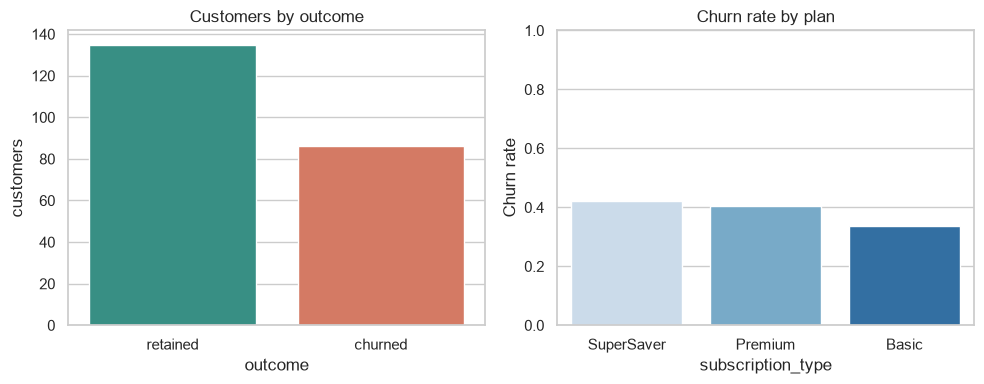

In [11]:
print(model.dtypes.to_string())
print()
print(f"Missing values:\n{model.isna().sum().loc[lambda s: s > 0].to_string()}")

plan = (
    model.groupby("subscription_type", as_index=False)
    .agg(customers=(ID_COLUMN, "size"), churn_rate=(LABEL, "mean"), mean_tenure_days=("tenure_days", "mean"))
    .sort_values("churn_rate", ascending=False)
)
display(plan)

association_rows = []
for column in NUMERIC_FEATURES:
    series = model[column]
    std = float(series.std(ddof=0))
    mean_churned = float(model.loc[model[LABEL].eq(1), column].mean())
    mean_retained = float(model.loc[model[LABEL].eq(0), column].mean())
    effect = (mean_churned - mean_retained) / std if std > 0 else np.nan
    association_rows.append(
        {
            "feature": column,
            "mean_when_churned": mean_churned,
            "mean_when_retained": mean_retained,
            "effect_churned_minus_retained": effect,
        }
    )
association = (
    pd.DataFrame(association_rows)
    .assign(abs_effect=lambda frame: frame["effect_churned_minus_retained"].abs())
    .sort_values("abs_effect", ascending=False)
    .drop(columns="abs_effect")
)
display(association.head(12))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
counts = model[LABEL].value_counts().rename({0: "retained", 1: "churned"}).reset_index()
counts.columns = ["outcome", "customers"]
sns.barplot(data=counts, x="outcome", y="customers", hue="outcome", ax=axes[0], palette=["#2a9d8f", "#e76f51"], legend=False)
axes[0].set_title("Customers by outcome")
sns.barplot(data=plan, x="subscription_type", y="churn_rate", hue="subscription_type", ax=axes[1], palette="Blues", legend=False)
axes[1].set_ylim(0, 1)
axes[1].set_title("Churn rate by plan")
axes[1].set_ylabel("Churn rate")
fig.tight_layout()